# éCO2mix exploration – French national electricity consumption

**Project:** MLOps course – Anomaly detection on the electrical network  

**Goal:** understand the RTE éCO2mix data before building the pipeline: time resolution, missing values, data quality, and whether removing the daily and weekly cycles is enough to detect anomalies.

**Data sources (Opendatasoft API, CSV export = 1 API call each):**
- `eco2mix-national-tr` : real-time data, last ~5 weeks, 15-min steps
- `eco2mix-national-cons-def` : consolidated history, here from 2023

**Contents**
1. Download the real-time data
2. Check the time grid and missing values
3. Plot consumption vs RTE forecast
4. Download and check the history (2023 → Aug 2026)
5. Daylight-saving problems: where are the duplicates and gaps?
6. Clean to a regular 30-min grid
7. MSTL test: remove daily + weekly cycles and look at the residual
8. Findings

## 1. Download the real-time data

In [1]:
import pandas as pd

URL = ("https://odre.opendatasoft.com/api/explore/v2.1/catalog/datasets/"
       "eco2mix-national-tr/exports/csv?delimiter=%3B")

df = pd.read_csv(URL, sep=";")
print(df.shape)
print(df.columns.tolist())
df.head()

(3840, 41)
['perimetre', 'nature', 'date', 'heure', 'date_heure', 'consommation', 'prevision_j1', 'prevision_j', 'fioul', 'charbon', 'gaz', 'nucleaire', 'eolien', 'eolien_terrestre', 'eolien_offshore', 'solaire', 'hydraulique', 'pompage', 'bioenergies', 'ech_physiques', 'taux_co2', 'ech_comm_angleterre', 'ech_comm_espagne', 'ech_comm_italie', 'ech_comm_suisse', 'ech_comm_allemagne_belgique', 'fioul_tac', 'fioul_cogen', 'fioul_autres', 'gaz_tac', 'gaz_cogen', 'gaz_ccg', 'gaz_autres', 'hydraulique_fil_eau_eclusee', 'hydraulique_lacs', 'hydraulique_step_turbinage', 'bioenergies_dechets', 'bioenergies_biomasse', 'bioenergies_biogaz', 'stockage_batterie', 'destockage_batterie']


,perimetre,nature,date,heure,date_heure,consommation,prevision_j1,prevision_j,fioul,charbon,...,gaz_ccg,gaz_autres,hydraulique_fil_eau_eclusee,hydraulique_lacs,hydraulique_step_turbinage,bioenergies_dechets,bioenergies_biomasse,bioenergies_biogaz,stockage_batterie,destockage_batterie
0,France,Données temps réel,2026-09-01,00:00,2026-08-31T22:00:00+00:00,42233.0,41500,41500.0,37.0,0.0,...,2243.0,0.0,2238.0,794.0,654.0,411.0,307.0,301.0,-51.0,1.0
1,France,Données temps réel,2026-09-01,00:15,2026-08-31T22:15:00+00:00,42256.0,40750,40750.0,37.0,0.0,...,2321.0,0.0,2234.0,976.0,778.0,408.0,307.0,301.0,-4.0,38.0
2,France,Données temps réel,2026-09-01,00:30,2026-08-31T22:30:00+00:00,41091.0,40000,40000.0,37.0,0.0,...,1715.0,0.0,2216.0,947.0,157.0,411.0,305.0,301.0,-16.0,0.0
3,France,Données temps réel,2026-09-01,00:45,2026-08-31T22:45:00+00:00,39517.0,39000,39000.0,37.0,0.0,...,1077.0,0.0,2174.0,928.0,157.0,408.0,305.0,301.0,-195.0,0.0
4,France,Données temps réel,2026-09-01,01:00,2026-08-31T23:00:00+00:00,38939.0,38000,38000.0,37.0,0.0,...,912.0,0.0,2184.0,798.0,158.0,412.0,305.0,301.0,-33.0,2.0


## 2. Time grid and missing values

In [2]:
df["date_heure"] = pd.to_datetime(df["date_heure"], utc=True)
df = df.sort_values("date_heure").reset_index(drop=True)

print("From:", df["date_heure"].min())
print("To:  ", df["date_heure"].max())
print("\nTime steps between rows:")
print(df["date_heure"].diff().value_counts().head())
print("\nDuplicated timestamps:", df["date_heure"].duplicated().sum())

print("\nMissing values:")
print(df[["consommation", "prevision_j1", "prevision_j"]].isna().sum())

last = df.loc[df["consommation"].notna(), "date_heure"].max()
print("\nLast actual consumption value:", last)
print("Rows after that (future forecasts only):", (df["date_heure"] > last).sum())

From: 2026-08-31 22:00:00+00:00
To:   2026-10-10 21:45:00+00:00

Time steps between rows:
date_heure
0 days 00:15:00    3839
Name: count, dtype: int64

Duplicated timestamps: 0

Missing values:
consommation    141
prevision_j1      0
prevision_j      96
dtype: int64

Last actual consumption value: 2026-10-09 10:30:00+00:00
Rows after that (future forecasts only): 141


## 3. Consumption vs RTE forecast (day before)

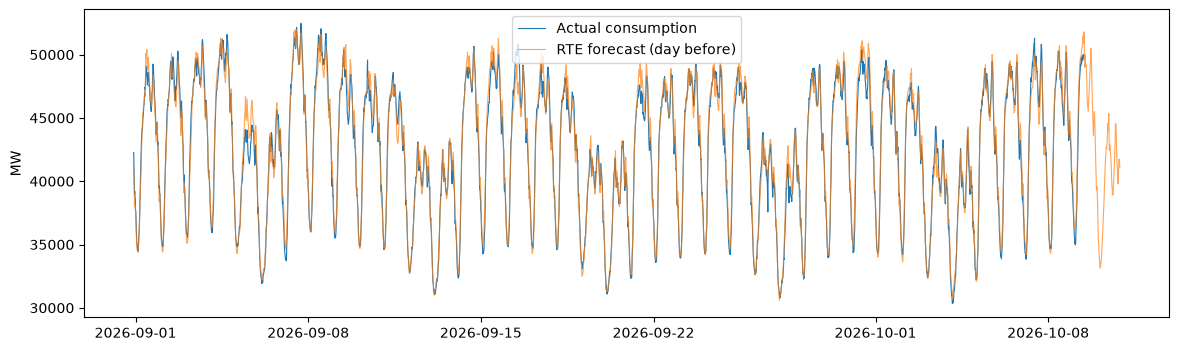

In [3]:
import matplotlib.pyplot as plt

past = df[df["consommation"].notna()]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(past["date_heure"], past["consommation"], label="Actual consumption", lw=0.8)
ax.plot(df["date_heure"], df["prevision_j1"], label="RTE forecast (day before)", lw=0.8, alpha=0.7)
ax.set_ylabel("MW")
ax.legend()
plt.show()

## 4. Historical data from 2023

In [4]:
import requests, io

HIST_URL = ("https://odre.opendatasoft.com/api/explore/v2.1/catalog/datasets/"
            "eco2mix-national-cons-def/exports/csv")
params = {
    "delimiter": ";",
    "select": "date_heure,consommation,prevision_j1,prevision_j",
    "where": "date_heure >= date'2023-01-01'",
}

r = requests.get(HIST_URL, params=params, timeout=300)
print("Status:", r.status_code)
r.raise_for_status()

hist = pd.read_csv(io.StringIO(r.text), sep=";")
hist["date_heure"] = pd.to_datetime(hist["date_heure"], utc=True)
hist = hist.sort_values("date_heure").reset_index(drop=True)
hist.to_parquet("hist_2023.parquet")   # saved locally, so we don't download again

print(hist.shape)
print("From:", hist["date_heure"].min(), " To:", hist["date_heure"].max())
print("\nTime steps:")
print(hist["date_heure"].diff().value_counts().head())
print("\nDuplicates:", hist["date_heure"].duplicated().sum())
print("\nMissing values:")
print(hist[["consommation", "prevision_j1", "prevision_j"]].isna().sum())

Status: 200
(128540, 4)
From: 2023-01-01 00:00:00+00:00  To: 2026-08-31 21:45:00+00:00

Time steps:
date_heure
0 days 00:15:00    128520
0 days 00:00:00        16
0 days 01:15:00         3
Name: count, dtype: int64

Duplicates: 16

Missing values:
consommation    64271
prevision_j1        0
prevision_j         0
dtype: int64


## 5. Daylight-saving problems

In [5]:
# 1. At which minutes is consumption filled in?
print("Minutes where consumption exists:")
print(hist.loc[hist["consommation"].notna(), "date_heure"].dt.minute.value_counts())

# 2. Where are the jumps?
step = hist["date_heure"].diff()
print("\nGaps (before -> after):")
for i in hist.index[step > pd.Timedelta("15min")]:
    print(" ", hist.loc[i - 1, "date_heure"], "->", hist.loc[i, "date_heure"])

# 3. Where are the duplicates? (daylight-saving)
print("\nDuplicated timestamps:")
print(hist[hist["date_heure"].duplicated(keep=False)].to_string())

Minutes where consumption exists:
date_heure
30    32135
0     32134
Name: count, dtype: int64

Gaps (before -> after):
  2023-10-28 23:45:00+00:00 -> 2023-10-29 01:00:00+00:00
  2024-10-26 23:45:00+00:00 -> 2024-10-27 01:00:00+00:00
  2025-10-25 23:45:00+00:00 -> 2025-10-26 01:00:00+00:00

Duplicated timestamps:
                      date_heure  consommation  prevision_j1  prevision_j
8068   2023-03-26 01:00:00+00:00       44716.0         42700        43700
8069   2023-03-26 01:00:00+00:00       44716.0         43600        44600
8070   2023-03-26 01:15:00+00:00           NaN         43500        43650
8071   2023-03-26 01:15:00+00:00           NaN         42700        43700
8072   2023-03-26 01:30:00+00:00       45124.0         43400        42700
8073   2023-03-26 01:30:00+00:00       45124.0         42700        43700
8074   2023-03-26 01:45:00+00:00           NaN         43150        44150
8075   2023-03-26 01:45:00+00:00           NaN         41900        41800
43684  2024-03-31 0

## 6. Clean to a regular 30-min grid

In [6]:
clean = hist.drop_duplicates(subset="date_heure", keep="first").set_index("date_heure")
clean = clean[clean.index.minute.isin([0, 30])]          # 30-minute resolution

full_index = pd.date_range(clean.index.min(), clean.index.max(), freq="30min", tz="UTC")
print("Missing half-hours before filling:", len(full_index.difference(clean.index)))

clean = clean.reindex(full_index)
clean.index.name = "date_heure"
clean = clean.interpolate(limit=4)                         # fill gaps of up to 2 hours only

print("Missing after filling:")
print(clean.isna().sum())
print(clean.shape)
clean.to_parquet("hist_2023_clean_30min.parquet")

Missing half-hours before filling: 6


Missing after filling:
consommation    0
prevision_j1    0
prevision_j     0
dtype: int64
(64268, 3)


## 7. MSTL test (June–August 2026)

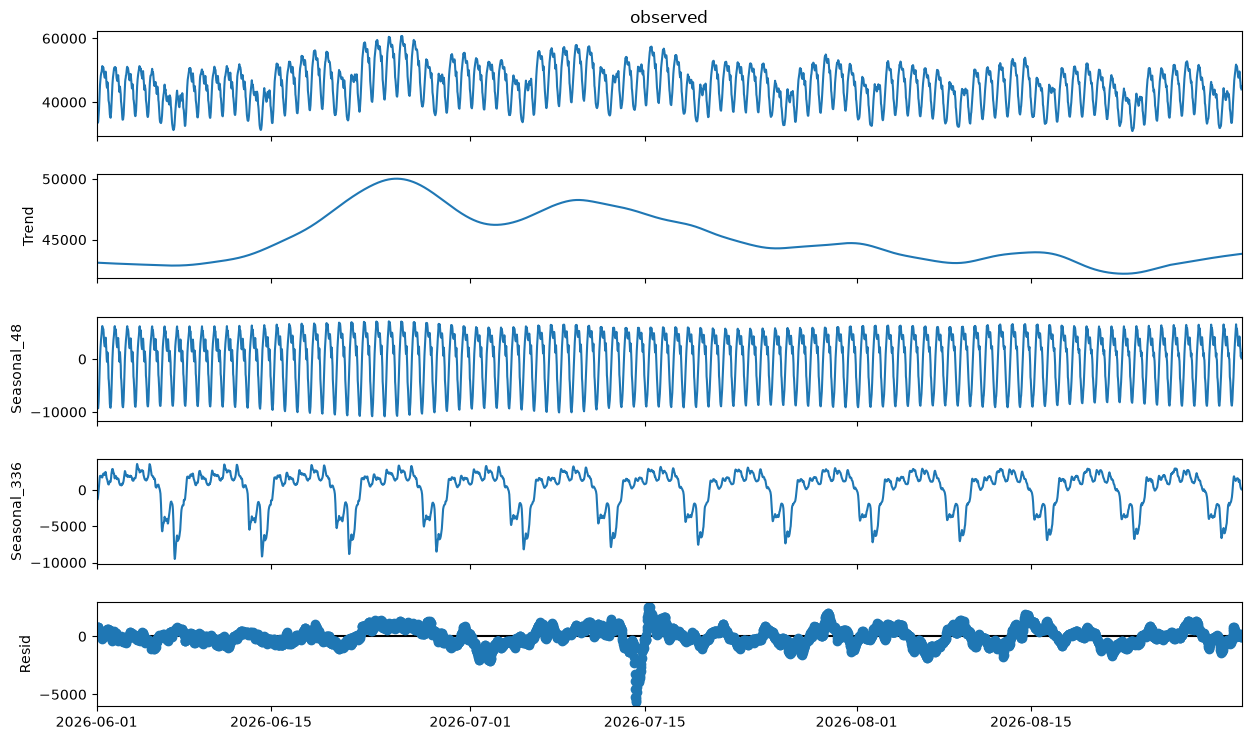

Half-hours with |z| > 4: 24
date_heure
2026-07-14 07:00:00+00:00   -8.203787
2026-07-14 06:30:00+00:00   -8.168030
2026-07-14 07:30:00+00:00   -7.837117
2026-07-14 08:00:00+00:00   -7.636114
2026-07-14 06:00:00+00:00   -7.582311
2026-07-14 08:30:00+00:00   -6.972664
2026-07-14 05:30:00+00:00   -6.643689
2026-07-14 09:00:00+00:00   -6.301224
2026-07-14 09:30:00+00:00   -6.030746
2026-07-14 10:00:00+00:00   -5.786477
Name: resid, dtype: float64


In [7]:
from statsmodels.tsa.seasonal import MSTL

y = clean["consommation"].loc["2026-06-01":]          # June to August 2026
res = MSTL(y, periods=(48, 336)).fit()                 # 48 = 1 day, 336 = 1 week (in half-hours)

fig = res.plot()
fig.set_size_inches(14, 8)
plt.show()

# Robust z-score on what's left after removing trend + daily + weekly cycles
r = res.resid
z = (r - r.median()) / (1.4826 * (r - r.median()).abs().median())
print("Half-hours with |z| > 4:", (z.abs() > 4).sum())
print(z[z.abs() > 4].sort_values(key=abs, ascending=False).head(10))

## Findings – éCO2mix exploration

**Data sources**
1. Real-time dataset (`eco2mix-national-tr`) keeps only ~5 weeks (current + previous month), 15-min resolution, published ~live, includes forecasts
2. Consolidated dataset (`eco2mix-national-cons-def`) gives history; it ends exactly where real-time starts (31 Aug 22:00 UTC) so **no gap**, one continuous series 2023

**Data quality**
3. "Missing" values in real-time data are **future rows**, not errors: `consommation` empty after now, `prevision_j` empty (96 = one day × 96 quarter-hours).
4. Work in **UTC** (`date_heure`) everywhere; convert to Paris time only for display.
5. History has consumption only every **30 min** (minutes 0 and 30) so project resolution = **30 min**.
6. 15-min grid of real-time sample is complete (no gaps, no duplicates).
7. **DST bug in RTE's UTC timestamps**: 01:00–01:45 UTC duplicated on the March change day, 00:00–00:45 UTC missing on the October change day. Fix: drop duplicates, regular 30-min grid, interpolate (6 half-hours filled for 2023–2026). ⚠️ Next change **25 Oct 2026** → test the live pipeline on it.

**Detection (MSTL test, Jun–Aug 2026, periods 48 & 336)**
8. Removing the daily + weekly cycles works: residual is flat, and the top anomaly is **14 July (Bastille Day)**, 07:00–12:00. → **Public holidays cause false alarms** – need a holiday calendar (`holidays` package).
9. Slow events (e.g. late-June heatwave) are absorbed into the **trend** and not flagged, also use the **forecast-gap baseline** (actual vs `prevision_j1`), since RTE's forecast already includes weather.